# LeNet-5 RGB — Reconnaissance des caractères manuscrits Tifinagh

## 1. Préparation de l’environnement

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
     if (p / "src" / "dataset.py").exists()),
    None
)
if ROOT is None:
    raise FileNotFoundError(
        "Project not found. Put this notebook in notebooks/ and open the project folder in VS Code."
    )

sys.path.insert(0, str(ROOT / "src"))
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

from dataset import check_dataset, load_datasets, load_image_paths, SEED
from model import build_lenet5
from evaluate import plot_history, evaluate_model, plot_feature_maps

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Project:", ROOT)
print("TensorFlow:", tf.__version__)
print("Results:", RESULTS_DIR)

Project: /Users/mac/Desktop/TPs/DL/4
TensorFlow: 2.22.0-rc0
Results: /Users/mac/Desktop/TPs/DL/4/results


## 2. Introduction et données

In [2]:
classes = check_dataset()
paths, labels, class_names = load_image_paths()

assert len(class_names) == 33, "Expected 33 Tifinagh classes."
assert len(paths) == len(labels), "Inconsistent paths/labels."

counts = np.bincount(labels, minlength=len(class_names))
class_distribution = pd.DataFrame({
    "class": class_names,
    "image_count": counts,
})

display(class_distribution)
print("Total images:", len(paths))
print("Min / max images per class:", int(counts.min()), int(counts.max()))

Number of classes: 33
Number of images: 25740
Classes: ['ya', 'yab', 'yach', 'yad', 'yadd', 'yae', 'yaf', 'yag', 'yagh', 'yagw', 'yah', 'yahh', 'yaj', 'yak', 'yakw', 'yal', 'yam', 'yan', 'yaq', 'yar', 'yarr', 'yas', 'yass', 'yat', 'yatt', 'yaw', 'yax', 'yay', 'yaz', 'yazz', 'yey', 'yi', 'yu']
Image size: (64, 64)
Image mode: RGB


,class,image_count
0,ya,780
1,yab,780
2,yach,780
3,yad,780
4,yadd,780
5,yae,780
6,yaf,780
7,yag,780
8,yagh,780
9,yagw,780


Total images: 25740
Min / max images per class: 780 780


## 3. Méthodes : préparation des données

In [3]:
BATCH_SIZE = 32
train_ds, val_ds, test_ds, class_names = load_datasets(batch_size=BATCH_SIZE)

for images, batch_labels in train_ds.take(1):
    print("Batch of images:", images.shape)
    print("Batch of labels:", batch_labels.shape)
    print("Pixel min/max:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

print("Number of classes:", len(class_names))

Dataset split:
Train: 18018
Validation: 3861
Test: 3861
Batch of images: (32, 32, 32, 3)
Batch of labels: (32,)
Pixel min/max: 0.1823529452085495 1.0
Number of classes: 33


### Exemples des caractères RGB après prétraitement

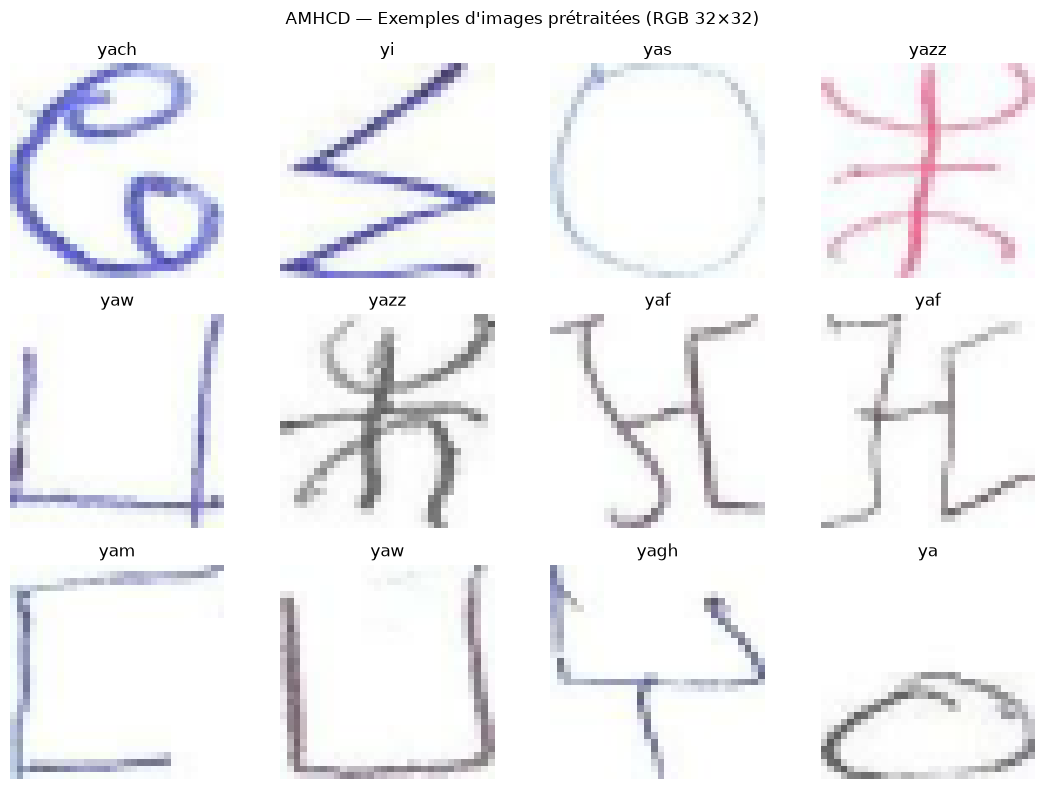

In [4]:
images_batch, labels_batch = next(iter(train_ds))
fig, axes = plt.subplots(3, 4, figsize=(11, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(images_batch[i].numpy())
    ax.set_title(class_names[int(labels_batch[i].numpy())])
    ax.axis("off")

fig.suptitle("AMHCD — Exemples d'images prétraitées (RGB 32×32)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "dataset_examples.png", dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. Architecture de LeNet-5

In [5]:
model_architecture = build_lenet5(
    input_shape=(32, 32, 3),
    num_classes=len(class_names)
)
model_architecture.summary()

# The expected count is specific to the Dense C5 implementation.
assert model_architecture.count_params() == 63961
assert model_architecture.output_shape == (None, 33)
print("Architecture verified: 63,961 parameters and 33 output classes.")

Model: "LeNet5_RGB"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_RGB (InputLayer)          │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C1 (Conv2D)                     │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2 (AveragePooling2D)           │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3 (Conv2D)                     │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4 (AveragePooling2D)           │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5 (Dense)                      │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6 (Dense)                      │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 33)             │         2,805 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,961 (249.85 KB)

 Trainable params: 63,961 (249.85 KB)

 Non-trainable params: 0 (0.00 B)

Architecture verified: 63,961 parameters and 33 output classes.


## 5. Entraînement — Adam et SGD

In [6]:
RUN_TRAINING = False  # Set True only if you need to retrain.
EPOCHS = 30

if RUN_TRAINING:
    from train import train_model

    comparison_new = {}
    for optimizer_name in ("adam", "sgd"):
        trained_model, history, metrics = train_model(
            train_ds, val_ds,
            optimizer=optimizer_name,
            epochs=EPOCHS,
        )
        comparison_new[optimizer_name] = metrics

    with open(RESULTS_DIR / "comparison.json", "w", encoding="utf-8") as f:
        json.dump(comparison_new, f, indent=4)
    with open(RESULTS_DIR / "class_names.json", "w", encoding="utf-8") as f:
        json.dump(class_names, f, indent=4)
    print("Training completed; models and histories saved.")
else:
    print("Existing models and histories will be loaded from results/.")

Existing models and histories will be loaded from results/.


## 6. Résultats : comparaison des optimiseurs sur Validation

In [7]:
required_files = [
    "comparison.json",
    "history_adam.json", "history_sgd.json",
    "lenet5_adam.keras", "lenet5_sgd.keras",
]
missing = [name for name in required_files if not (RESULTS_DIR / name).exists()]
if missing:
    raise FileNotFoundError(
        "Missing training outputs: " + ", ".join(missing)
        + ". Run: python src/train.py --optimizer both --epochs 30"
    )

with open(RESULTS_DIR / "comparison.json", encoding="utf-8") as f:
    comparison = json.load(f)

histories = {}
for optimizer_name in ("adam", "sgd"):
    with open(RESULTS_DIR / f"history_{optimizer_name}.json", encoding="utf-8") as f:
        histories[optimizer_name] = json.load(f)

best_optimizer = min(comparison, key=lambda name: comparison[name]["val_loss"])

summary_val = pd.DataFrame([
    {
        "Optimizer": name.upper(),
        "Best epoch": metrics["best_epoch"],
        "Validation accuracy (%)": 100 * metrics["val_accuracy"],
        "Validation loss": metrics["val_loss"],
    }
    for name, metrics in comparison.items()
]).sort_values("Validation loss")

display(summary_val.style.format({
    "Validation accuracy (%)": "{:.2f}",
    "Validation loss": "{:.4f}",
}))
print("Selected optimizer (lowest validation loss):", best_optimizer.upper())
summary_val.to_csv(RESULTS_DIR / "validation_comparison.csv", index=False)

,Optimizer,Best epoch,Validation accuracy (%),Validation loss
1,SGD,24,98.34,0.0595
0,ADAM,24,97.36,0.0930


Selected optimizer (lowest validation loss): SGD


### Comparaison des courbes de validation pour Adam et SGD

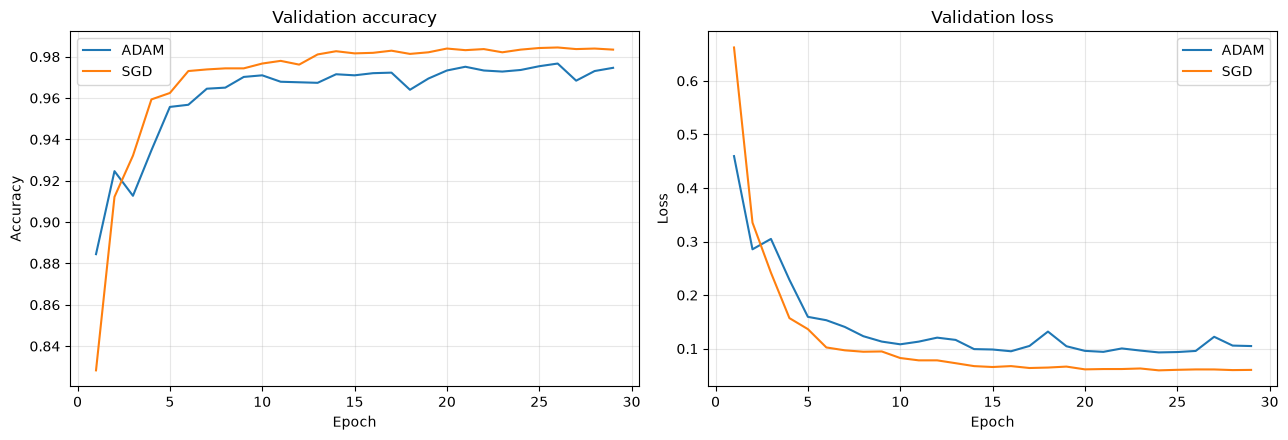

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for opt_name, hist in histories.items():
    epoch_nums = np.arange(1, len(hist["val_accuracy"]) + 1)
    axes[0].plot(epoch_nums, hist["val_accuracy"], label=opt_name.upper())
    axes[1].plot(epoch_nums, hist["val_loss"], label=opt_name.upper())

axes[0].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].set(title="Validation loss", xlabel="Epoch", ylabel="Loss")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
fig.savefig(RESULTS_DIR / "optimizer_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

### Courbes Train / Validation du modèle retenu

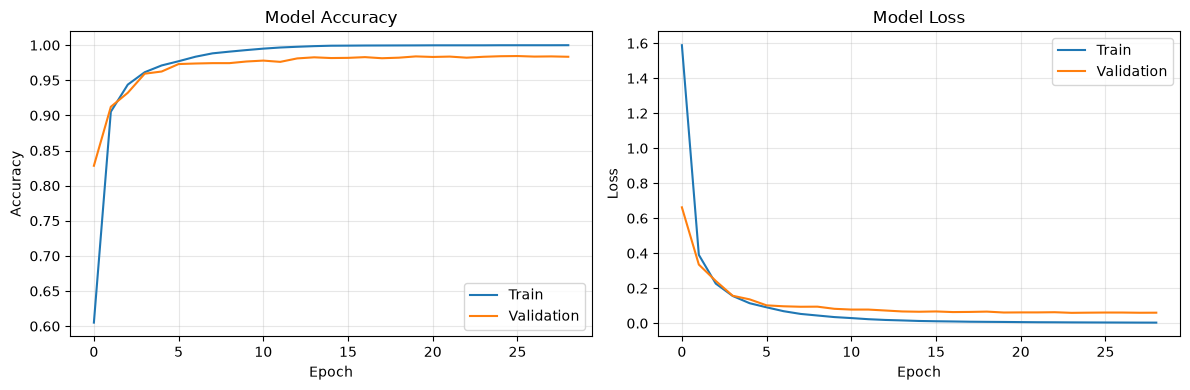

In [9]:
plot_history(histories[best_optimizer], save=True)

## 7. Évaluation finale — Ensemble Test

Final model: LeNet5_RGB
Selected optimizer: SGD
 Test Results 
accuracy: 0.9806
loss: 0.0620
Accuracy: 0.9806
Macro F1-score: 0.9806
 Classification Report 
              precision    recall  f1-score   support

          ya       1.00      1.00      1.00       117
         yab       1.00      0.98      0.99       117
        yach       0.98      0.97      0.97       117
         yad       0.98      0.98      0.98       117
        yadd       0.99      0.99      0.99       117
         yae       0.98      1.00      0.99       117
         yaf       0.99      0.99      0.99       117
         yag       0.96      1.00      0.98       117
        yagh       0.99      1.00      1.00       117
        yagw       0.97      0.97      0.97       117
         yah       0.99      0.98      0.99       117
        yahh       0.98      0.99      0.99       117
         yaj       0.97      0.98      0.97       117
         yak       0.99      0.97      0.98       117
        yakw       1.00      0.9

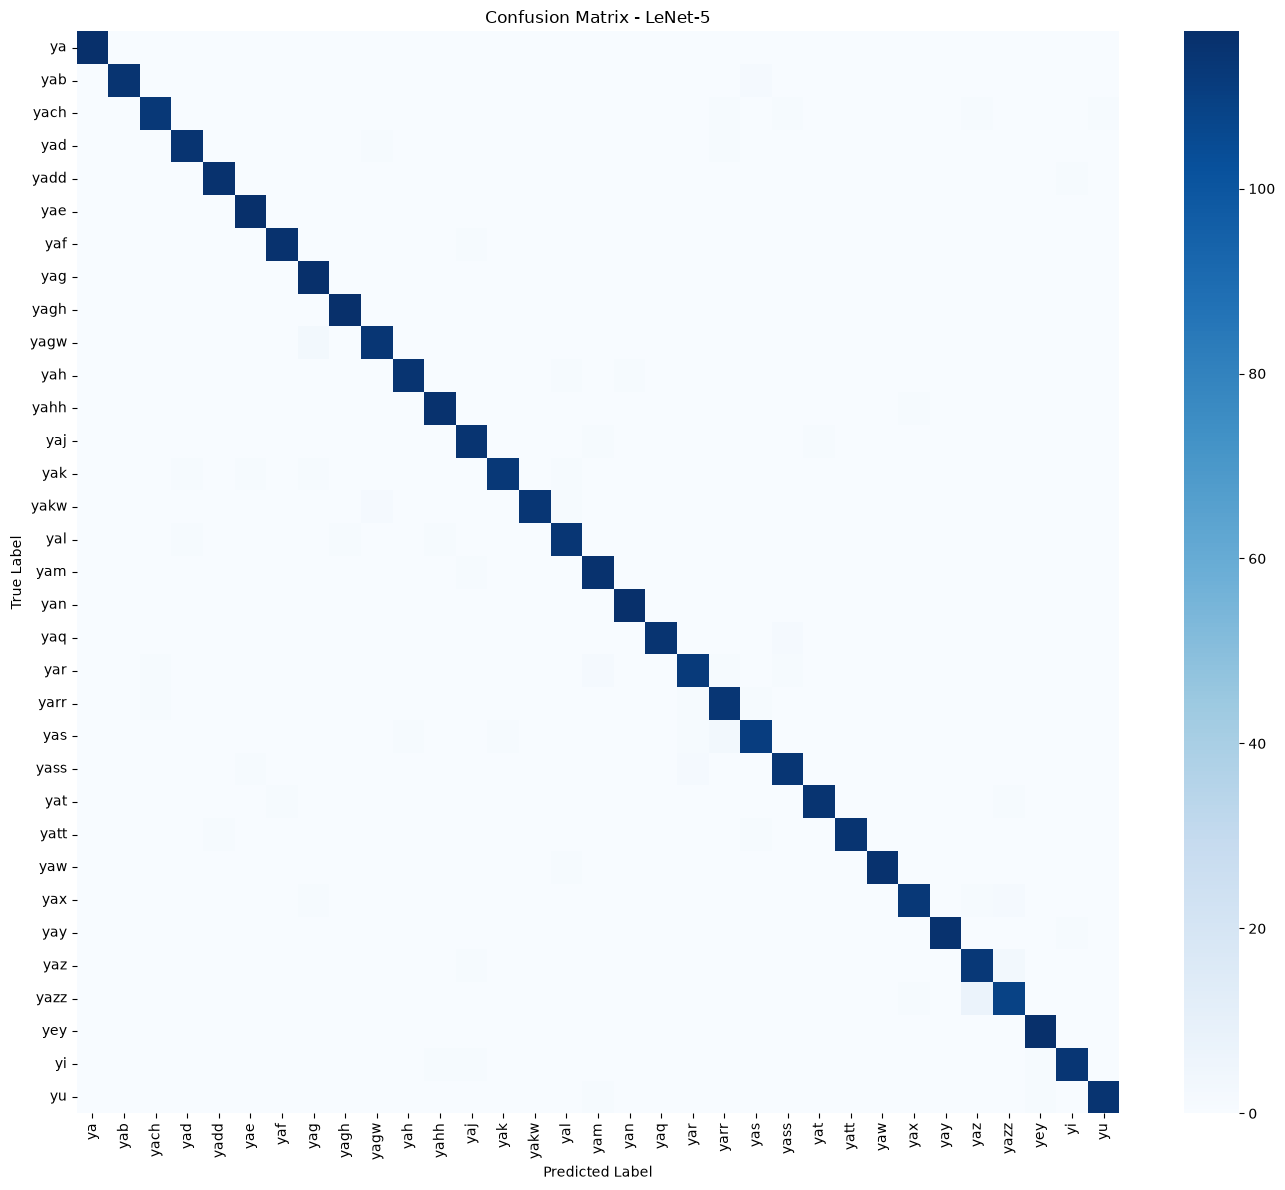

Final TEST accuracy: 98.0575% (3786/3861)
Final macro-F1: 0.9806


In [10]:
model = tf.keras.models.load_model(
    RESULTS_DIR / f"lenet5_{best_optimizer}.keras"
)

print("Final model:", model.name)
print("Selected optimizer:", best_optimizer.upper())

report, cm = evaluate_model(
    model=model,
    test_ds=test_ds,
    class_names=class_names,
    save=True,
)

n_test = int(cm.sum())
test_accuracy = float(np.trace(cm) / n_test)
print(f"Final TEST accuracy: {test_accuracy:.4%} ({int(np.trace(cm))}/{n_test})")
print(f"Final macro-F1: {report['macro avg']['f1-score']:.4f}")

### Matrice de confusion normalisée (par classe réelle)

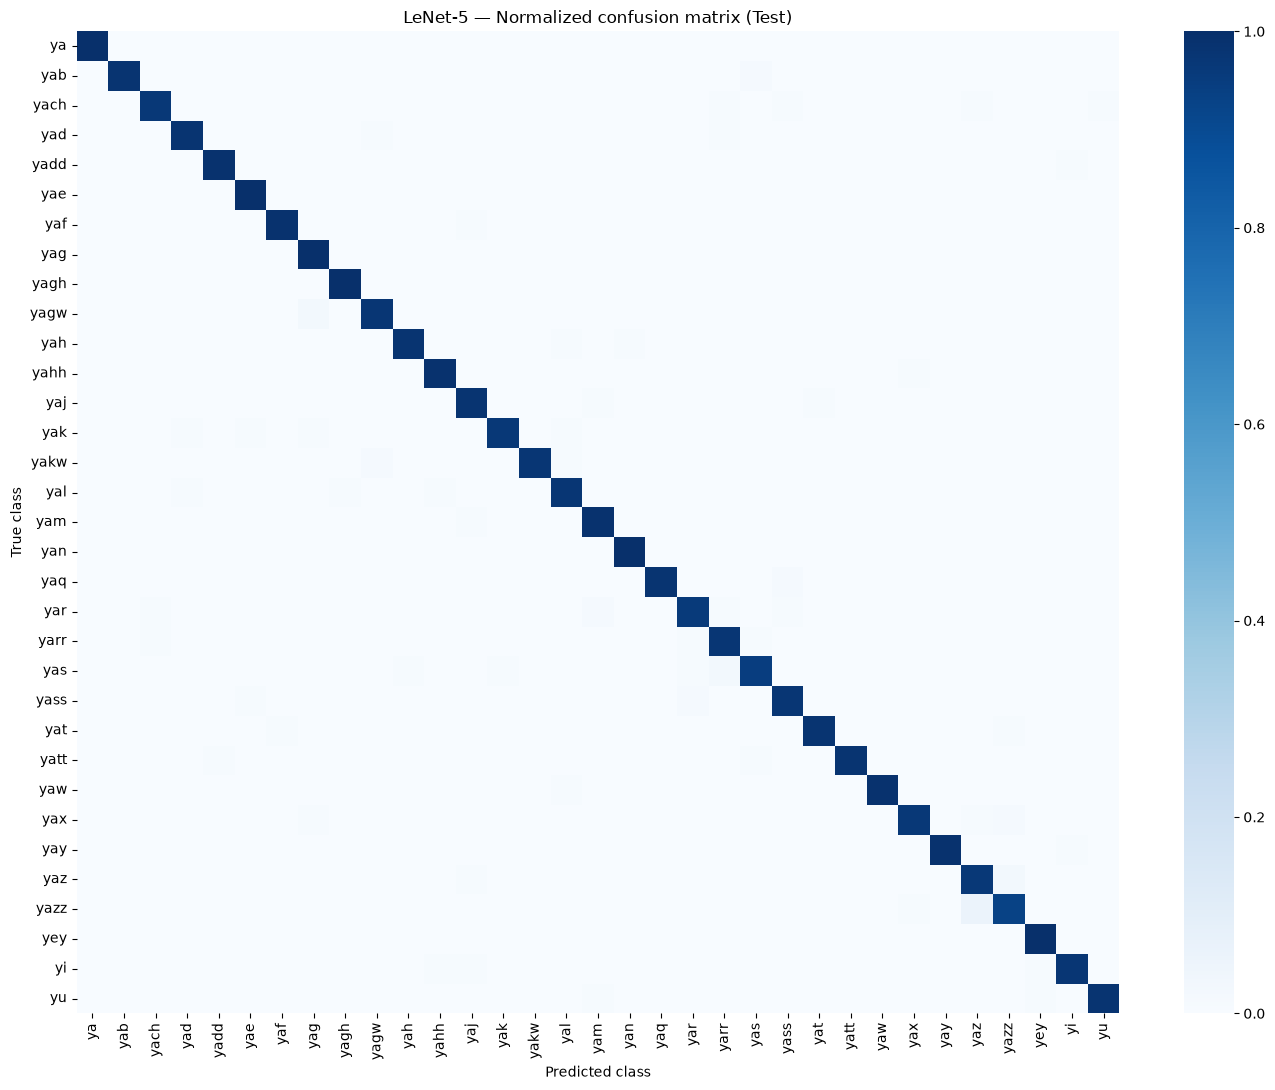

In [11]:
row_totals = cm.sum(axis=1, keepdims=True)
cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0,
)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    cm_normalized,
    cmap="Blues", vmin=0, vmax=1,
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax,
)
ax.set(
    title="LeNet-5 — Normalized confusion matrix (Test)",
    xlabel="Predicted class", ylabel="True class",
)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrix_normalized.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

### Performances par classe

,class,precision,recall,f1_score,support
29,yazz,0.948,0.932,0.940,117
28,yaz,0.926,0.966,0.946,117
21,yas,0.965,0.949,0.957,117
19,yar,0.966,0.957,0.961,117
20,yarr,0.950,0.974,0.962,117
15,yal,0.966,0.974,0.970,117
22,yass,0.966,0.974,0.970,117
26,yax,0.983,0.966,0.974,117
2,yach,0.983,0.966,0.974,117
9,yagw,0.974,0.974,0.974,117


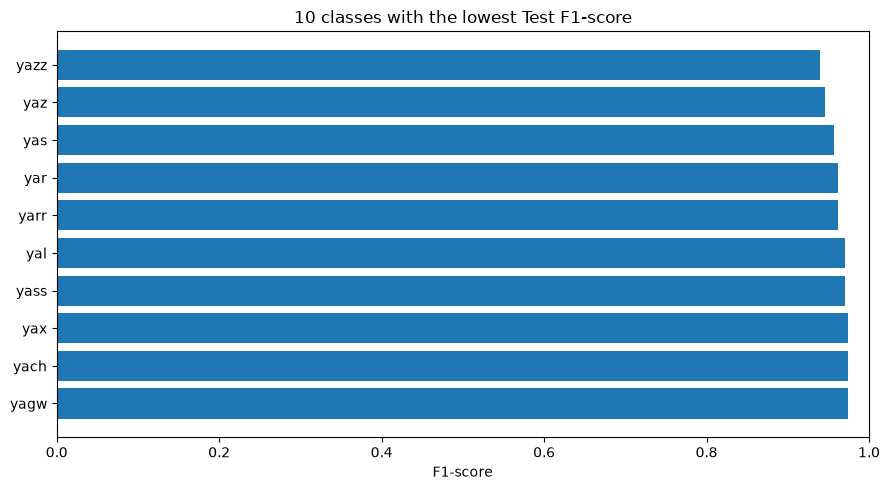

In [12]:
per_class = pd.DataFrame([
    {
        "class": name,
        "precision": report[name]["precision"],
        "recall": report[name]["recall"],
        "f1_score": report[name]["f1-score"],
        "support": int(report[name]["support"]),
    }
    for name in class_names
]).sort_values("f1_score")

per_class.to_csv(RESULTS_DIR / "per_class_metrics.csv", index=False)
display(per_class.style.format({
    "precision": "{:.3f}", "recall": "{:.3f}", "f1_score": "{:.3f}"
}))

worst = per_class.head(10)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(worst["class"], worst["f1_score"])
ax.invert_yaxis()
ax.set(xlabel="F1-score", title="10 classes with the lowest Test F1-score", xlim=(0, 1))
fig.tight_layout()
fig.savefig(RESULTS_DIR / "lowest_f1_classes.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## 8. Résultats qualitatifs — Erreurs de classification

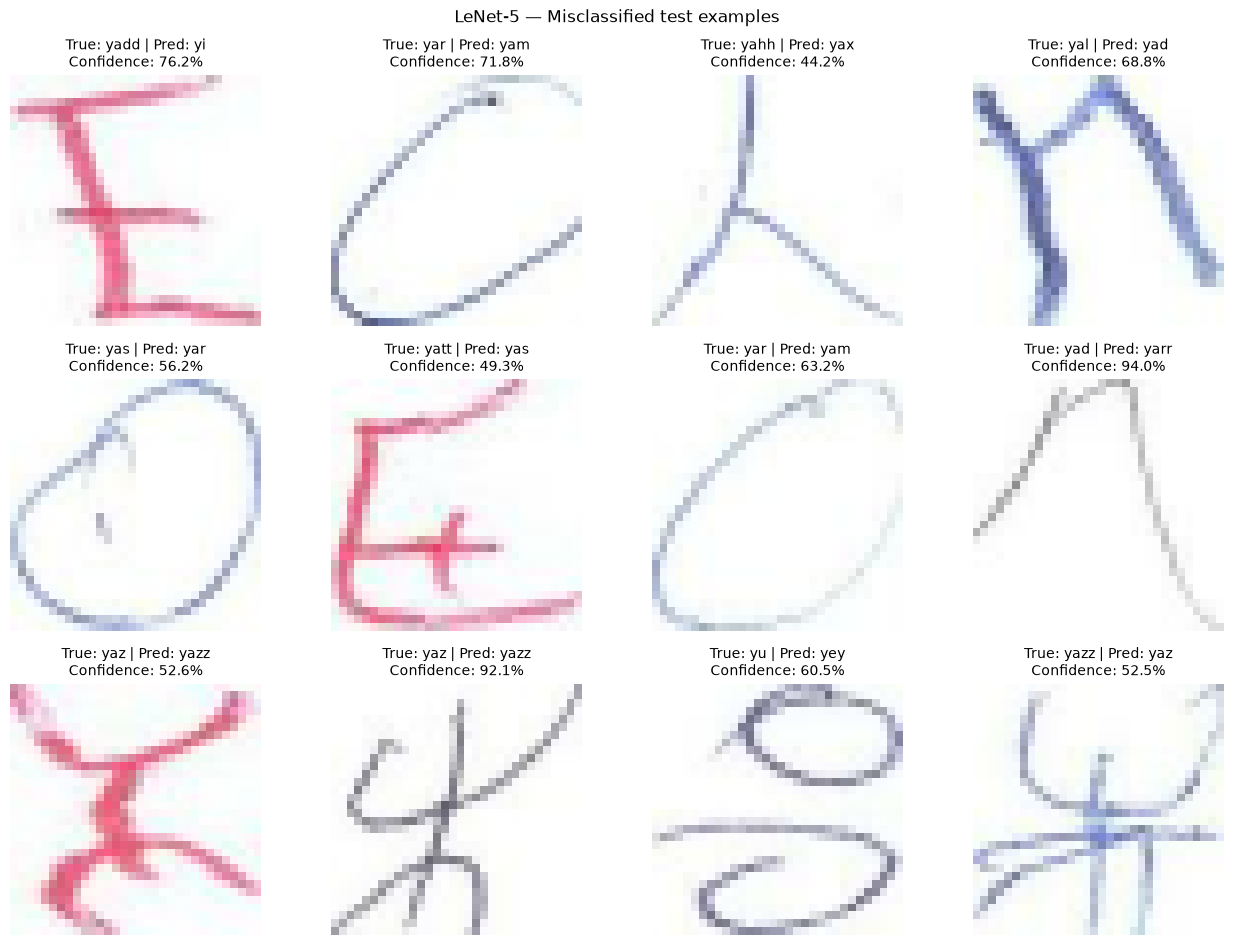

Displayed 12 test errors.


In [13]:
max_errors = 12
errors = []

for img_batch, label_batch in test_ds:
    probabilities = model.predict_on_batch(img_batch)
    predicted = np.argmax(probabilities, axis=1)
    real = label_batch.numpy()

    for i in np.flatnonzero(predicted != real):
        errors.append((
            img_batch[i].numpy(),
            int(real[i]),
            int(predicted[i]),
            float(probabilities[i, predicted[i]])
        ))
        if len(errors) >= max_errors:
            break
    if len(errors) >= max_errors:
        break

if not errors:
    print("No misclassified example found on the test set.")
else:
    ncols = 4
    nrows = int(np.ceil(len(errors) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.2 * nrows), squeeze=False)

    for ax in axes.flat:
        ax.axis("off")

    for ax, (img, true_id, pred_id, confidence) in zip(axes.flat, errors):
        ax.imshow(img)
        ax.set_title(
            f"True: {class_names[true_id]} | Pred: {class_names[pred_id]}\n"
            f"Confidence: {confidence:.1%}",
            fontsize=10,
        )
        ax.axis("off")

    fig.suptitle("LeNet-5 — Misclassified test examples")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "misclassified_examples.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Displayed {len(errors)} test errors.")

## 9. Cartes de caractéristiques (*feature maps*)

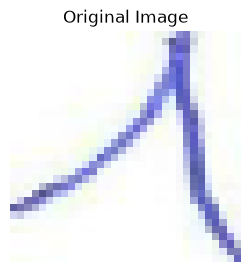

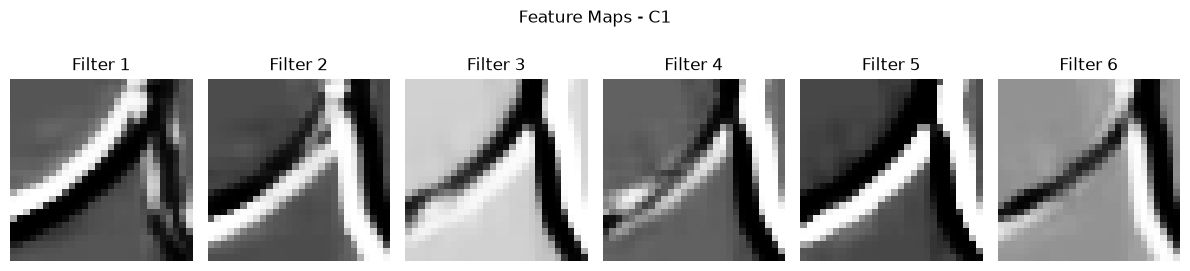

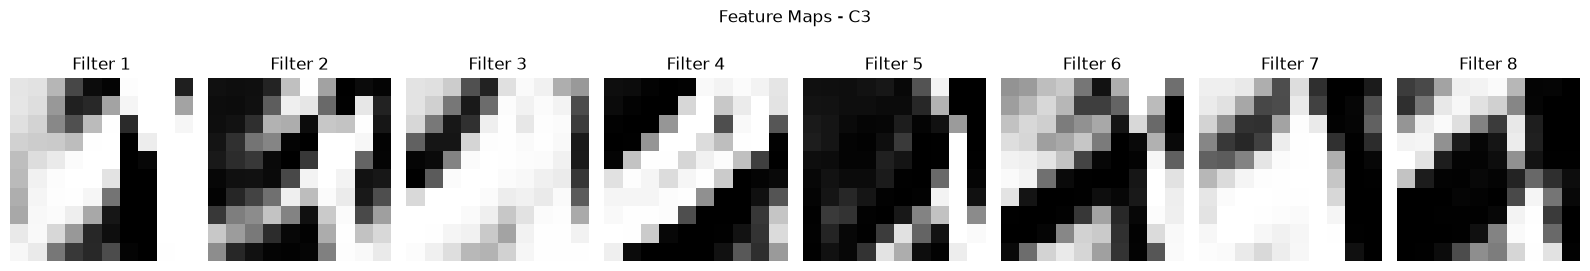

In [14]:
plot_feature_maps(
    model=model,
    test_ds=test_ds,
    max_maps=8,
    save=True,
)

## 10. Synthèse des résultats pour l’article IMRAD

In [15]:
final_summary = {
    "dataset": "AMHCD_64",
    "input_shape": [32, 32, 3],
    "num_classes": len(class_names),
    "architecture": "LeNet-5 RGB, tanh, average pooling",
    "train_validation_test_split": [0.70, 0.15, 0.15],
    "optimizer_selected_on": "minimum validation loss",
    "selected_optimizer": best_optimizer,
    "best_validation_epoch": int(comparison[best_optimizer]["best_epoch"]),
    "best_validation_loss": float(comparison[best_optimizer]["val_loss"]),
    "best_validation_accuracy": float(comparison[best_optimizer]["val_accuracy"]),
    "test_accuracy": test_accuracy,
    "test_macro_precision": float(report["macro avg"]["precision"]),
    "test_macro_recall": float(report["macro avg"]["recall"]),
    "test_macro_f1": float(report["macro avg"]["f1-score"]),
    "test_support": n_test,
}

with open(RESULTS_DIR / "final_summary.json", "w", encoding="utf-8") as f:
    json.dump(final_summary, f, indent=4, ensure_ascii=False)

print(json.dumps(final_summary, indent=4, ensure_ascii=False))

{
    "dataset": "AMHCD_64",
    "input_shape": [
        32,
        32,
        3
    ],
    "num_classes": 33,
    "architecture": "LeNet-5 RGB, tanh, average pooling",
    "train_validation_test_split": [
        0.7,
        0.15,
        0.15
    ],
    "optimizer_selected_on": "minimum validation loss",
    "selected_optimizer": "sgd",
    "best_validation_epoch": 24,
    "best_validation_loss": 0.059491757303476334,
    "best_validation_accuracy": 0.9834240078926086,
    "test_accuracy": 0.9805749805749806,
    "test_macro_precision": 0.9807595283427428,
    "test_macro_recall": 0.9805749805749805,
    "test_macro_f1": 0.980593903114131,
    "test_support": 3861
}


### Vérification des fichiers générés

In [16]:
generated_files = sorted(p.name for p in RESULTS_DIR.iterdir() if p.is_file())
print("Files available in results/:")
for filename in generated_files:
    print(" -", filename)

print("Notebook completed. The figures and metrics above can be used in the IMRAD report.")

Files available in results/:
 - class_names.json
 - comparison.json
 - confusion_matrix.png
 - confusion_matrix_normalized.png
 - dataset_examples.png
 - feature_maps_C1.png
 - feature_maps_C3.png
 - final_summary.json
 - history_adam.csv
 - history_adam.json
 - history_sgd.csv
 - history_sgd.json
 - lenet5_adam.keras
 - lenet5_sgd.keras
 - lowest_f1_classes.png
 - metrics.json
 - misclassified_examples.png
 - optimizer_comparison.png
 - original_image.png
 - per_class_metrics.csv
 - training_history.png
 - validation_comparison.csv
Notebook completed. The figures and metrics above can be used in the IMRAD report.
